# CrowdGuard: Kaggle Handoff Evaluation and Report Figures (revised)

This notebook evaluates the **10 saved CrowdGuard handoffs** without retraining. It clones the project code from GitHub, reads `.pt` files from an attached Kaggle Dataset, invokes the repository's validation/evaluation scripts, and generates report-ready tables and figures.

**Kaggle setup before running:**
1. Enable **Internet** in Notebook settings (GitHub and the CIFAR-10 download need it).
2. Use **Add Input** to attach the Kaggle Dataset containing the ten `.pt` handoffs, and set `KAGGLE_INPUT` in the setup cell to that folder.
3. Run all cells top to bottom. Outputs go to `/kaggle/working/crowdguard_report_outputs`.

**What changed in this revision:** partition labels are inferred from the file name when a handoff's config has no `partition` key (three older IID handoffs); a code-version audit compares git commits and source hashes across the ten runs; detection recall is reported over rounds where the attacker was active (the attack starts at round 1); the five tau line plots are replaced by a frequency-separation plot, a tau window table and FP/FN heatmaps; curves and detection figures are faceted/compact; one consolidated results table is exported.

This notebook does not retrain models. It only plots metrics that the handoff/evaluator supplies; it does not invent training-loss or runtime histories that were never saved.

## 0. Clone GitHub and configure Kaggle paths

The source repository is cloned from the `crowdguard-branch` branch (optionally pinned to a commit with `PIN_COMMIT`). The handoff folder is set explicitly with `KAGGLE_INPUT`; handoffs are discovered recursively below it. The environment (Python, PyTorch, CUDA, GPU) is recorded to `environment.json`.

In [1]:
from pathlib import Path
import os, sys, json, subprocess, re, warnings, platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---- GitHub source ----
REPO_URL = "https://github.com/clearlynew/Verifiable-Federated-Unlearning.git"
REPO_BRANCH = "crowdguard-branch"
PIN_COMMIT = ""   # optional: paste a full commit hash here to evaluate with exactly that code
WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
REPO_ROOT = WORK_DIR / "Verifiable-Federated-Unlearning"
REPO_DIR = REPO_ROOT / "CrowdGuard"  # contains evaluate_handoff.py and validate_handoff.py

if not (REPO_DIR / "evaluate_handoff.py").exists():
    if REPO_ROOT.exists():
        subprocess.run(["git", "-C", str(REPO_ROOT), "fetch", "--depth", "1", "origin", REPO_BRANCH], check=True)
        subprocess.run(["git", "-C", str(REPO_ROOT), "checkout", "-f", REPO_BRANCH], check=True)
        subprocess.run(["git", "-C", str(REPO_ROOT), "reset", "--hard", f"origin/{REPO_BRANCH}"], check=True)
    else:
        subprocess.run(["git", "clone", "--branch", REPO_BRANCH, REPO_URL, str(REPO_ROOT)], check=True)
if PIN_COMMIT:
    subprocess.run(["git", "-C", str(REPO_ROOT), "fetch", "origin", PIN_COMMIT], check=False)
    subprocess.run(["git", "-C", str(REPO_ROOT), "checkout", "-f", PIN_COMMIT], check=True)

# ---- Kaggle Dataset containing the .pt handoffs ----
KAGGLE_INPUT = Path("/kaggle/input/datasets/jameswalter12345/crowdguard-handoffs/Handoff_Files_Crowdguard")
HANDOFF_DIR = KAGGLE_INPUT

DATA_ROOT = WORK_DIR / "cifar10_data"
OUTPUT_DIR = WORK_DIR / "crowdguard_report_outputs"

REPO_ROOT = REPO_ROOT.resolve()
REPO_DIR = REPO_DIR.resolve()
HANDOFF_DIR = HANDOFF_DIR.resolve()
DATA_ROOT = DATA_ROOT.resolve()
OUTPUT_DIR = OUTPUT_DIR.resolve()
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert (REPO_DIR / "evaluate_handoff.py").exists(), f"Cannot find evaluate_handoff.py at {REPO_DIR}"
assert (REPO_DIR / "validate_handoff.py").exists(), f"Cannot find validate_handoff.py at {REPO_DIR}"
assert HANDOFF_DIR.exists(), f"Handoff input path does not exist: {HANDOFF_DIR}"
sys.path.insert(0, str(REPO_DIR))

commit = subprocess.run(["git", "-C", str(REPO_ROOT), "rev-parse", "HEAD"], check=True, capture_output=True, text=True).stdout.strip()
env_info = {
    "evaluation_notebook_repo_commit": commit,
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "cuda": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "platform": platform.platform(),
}
with open(OUTPUT_DIR / "environment.json", "w") as f:
    json.dump(env_info, f, indent=2)
print("Repository:", REPO_URL, "| branch:", REPO_BRANCH)
for k, v in env_info.items(): print(f"{k:34s} {v}")
print("Source directory:", REPO_DIR)
print("Handoff search root:", HANDOFF_DIR)
print("Output directory:", OUTPUT_DIR)

Cloning into '/kaggle/working/Verifiable-Federated-Unlearning'...


Repository: https://github.com/clearlynew/Verifiable-Federated-Unlearning.git | branch: crowdguard-branch
evaluation_notebook_repo_commit    4e2a8791d20fea5ed1c86ff63282f707054f6772
python                             3.13.15
torch                              2.11.0+cu128
cuda                               12.8
gpu                                Tesla T4
platform                           Linux-6.18.48+-x86_64-with-glibc2.39
Source directory: /kaggle/working/Verifiable-Federated-Unlearning/CrowdGuard
Handoff search root: /kaggle/input/datasets/jameswalter12345/crowdguard-handoffs/Handoff_Files_Crowdguard
Output directory: /kaggle/working/crowdguard_report_outputs


## 1. Discover handoffs and check the expected experiment matrix

The notebook recursively discovers `.pt` files under `KAGGLE_INPUT`. Attach a dataset containing only the ten intended handoffs. Filenames are listed for audit; experiment metadata is read from inside each handoff.

In [2]:
handoff_paths = sorted(HANDOFF_DIR.rglob("*.pt"))
if not handoff_paths:
    raise FileNotFoundError(
        f"No .pt handoffs found under {HANDOFF_DIR}. In Kaggle, click Add Input and attach your handoff dataset."
    )
print(f"Found {len(handoff_paths)} .pt file(s)")
for p in handoff_paths:
    print(f" - {p.name} ({p.stat().st_size / (1024**2):.1f} MiB) | {p}")

if len(handoff_paths) != 10:
    warnings.warn(
        f"Expected 10 handoffs, found {len(handoff_paths)}. Make sure the input dataset contains only the intended experiment artifacts."
    )

HANDOFF_PATH_BY_NAME = {p.name: p for p in handoff_paths}

Found 10 .pt file(s)
 - handoff_005pmr_seed10_iid.pt (243.9 MiB) | /kaggle/input/datasets/jameswalter12345/crowdguard-handoffs/Handoff_Files_Crowdguard/handoff_005pmr_seed10_iid.pt
 - handoff_005pmr_seed42_iid.pt (243.9 MiB) | /kaggle/input/datasets/jameswalter12345/crowdguard-handoffs/Handoff_Files_Crowdguard/handoff_005pmr_seed42_iid.pt
 - handoff_010pmr_seed10_dirichlet_05alpha.pt (243.9 MiB) | /kaggle/input/datasets/jameswalter12345/crowdguard-handoffs/Handoff_Files_Crowdguard/handoff_010pmr_seed10_dirichlet_05alpha.pt
 - handoff_010pmr_seed10_iid.pt (243.9 MiB) | /kaggle/input/datasets/jameswalter12345/crowdguard-handoffs/Handoff_Files_Crowdguard/handoff_010pmr_seed10_iid.pt
 - handoff_010pmr_seed42_iid.pt (243.9 MiB) | /kaggle/input/datasets/jameswalter12345/crowdguard-handoffs/Handoff_Files_Crowdguard/handoff_010pmr_seed42_iid.pt
 - handoff_045pmr_seed10_dirichlet_05alpha.pt (243.9 MiB) | /kaggle/input/datasets/jameswalter12345/crowdguard-handoffs/Handoff_Files_Crowdguard/handof

## 2. Validate handoff integrity

This runs the project's validator for each file. Validation checks the schema, round history, FedAvg bookkeeping (the identity the unlearning stage relies on), commit–reveal consistency, recomputation of each round's detected set from the revealed votes, and dataset split bookkeeping. It does **not** re-run HLBIM or re-test detection quality, and a successful validation does not prove the scientific conclusions; it verifies internal consistency.

In [3]:
validation_rows = []
for path in handoff_paths:
    cmd = [sys.executable, str(REPO_DIR / "validate_handoff.py"), str(path)]
    proc = subprocess.run(cmd, cwd=REPO_DIR, capture_output=True, text=True)
    validation_rows.append({
        "file": path.name,
        "valid": proc.returncode == 0,
        "return_code": proc.returncode,
        "stdout": proc.stdout[-4000:],
        "stderr": proc.stderr[-4000:],
    })
validation_df = pd.DataFrame(validation_rows)
display(validation_df[["file", "valid", "return_code"]])
validation_df.to_csv(OUTPUT_DIR / "handoff_validation_summary.csv", index=False)
failed = validation_df.loc[~validation_df["valid"], "file"].tolist()
if failed:
    print("\nWARNING: validation failed for these handoffs. Inspect validation output before using their results:")
    for f in failed: print(" -", f)
else:
    print("All discovered handoffs passed the validator.")

,file,valid,return_code
0,handoff_005pmr_seed10_iid.pt,True,0
1,handoff_005pmr_seed42_iid.pt,True,0
2,handoff_010pmr_seed10_dirichlet_05alpha.pt,True,0
3,handoff_010pmr_seed10_iid.pt,True,0
4,handoff_010pmr_seed42_iid.pt,True,0
5,handoff_045pmr_seed10_dirichlet_05alpha.pt,True,0
6,handoff_045pmr_seed10_iid.pt,True,0
7,handoff_0pmr_seed10_dirichlet_05alpha.pt,True,0
8,handoff_0pmr_seed10_iid.pt,True,0
9,handoff_0pmr_seed42_iid.pt,True,0


All discovered handoffs passed the validator.


## 3. Load handoff metadata safely

This cell extracts configuration, detection-history and **code-version** metadata for indexing and audit. Model evaluation is delegated to `evaluate_handoff.py`. `torch.load(..., weights_only=True)` is used as in the repository's evaluator.

Three older IID handoffs have no `partition` key in their saved config. Their partition is inferred from the file name, and `partition_recorded` keeps the raw value so those runs stay identifiable.

In [4]:
def infer_partition_name(recorded, filename):
    """Use the recorded partition if valid; otherwise infer it from the file name."""
    rec = str(recorded).lower() if recorded is not None else ""
    if rec in {"iid", "dirichlet"}:
        return rec
    name = str(filename).lower()
    if "dirichlet" in name:
        return "dirichlet"
    if "iid" in name:
        return "iid"
    return "unknown"

def run_label(partition, alpha, pmr, seed):
    p = "IID" if partition == "iid" else f"Dir({alpha})"
    return f"{p} | PMR {float(pmr):.2f} | s{int(seed)}"

PART_RANK = {"iid": 0, "dirichlet": 1, "unknown": 2}

In [5]:
def load_handoff(path):
    return torch.load(path, map_location="cpu", weights_only=True)

def metadata_row(path):
    h = load_handoff(path)
    c = h.get("config", {})
    part = infer_partition_name(c.get("partition"), path.name)
    alpha = c.get("dirichlet_alpha") if part == "dirichlet" else np.nan
    history = h.get("round_history", [])
    truth = h.get("ground_truth_malicious_clients", [])
    counts = h.get("detection_counts", {})
    env = h.get("environment") or {}
    return {
        "file": path.name,
        "schema_version": h.get("schema_version"),
        "partition": part,
        "partition_recorded": c.get("partition"),
        "dirichlet_alpha": alpha,
        "pmr": c.get("pmr"),
        "seed": c.get("seed"),
        "rounds_configured": c.get("rounds"),
        "rounds_saved": len(history),
        "num_clients": c.get("num_clients"),
        "attack_start_round": c.get("attack_start_round"),
        "num_malicious_ground_truth": len(truth),
        "ground_truth_clients": ", ".join(sorted(truth)),
        "final_M_rule_saved": h.get("final_M_rule"),
        "final_M_saved": ", ".join(sorted(h.get("final_M", []))),
        "final_M_tau_saved": c.get("final_m_tau"),
        "tamper_test": c.get("tamper_test", False),
        "n_detection_count_entries": len(counts),
        "run_git_commit": env.get("git_commit"),
        "run_git_dirty": env.get("git_dirty"),
        "run_torch": (env.get("packages") or {}).get("torch"),
        "run_source_sha256": json.dumps(env.get("source_sha256") or {}, sort_keys=True),
    }

metadata_df = pd.DataFrame([metadata_row(p) for p in handoff_paths])
metadata_df["_rank"] = metadata_df["partition"].map(PART_RANK)
metadata_df = metadata_df.sort_values(["_rank", "pmr", "seed"]).drop(columns="_rank").reset_index(drop=True)
display(metadata_df.drop(columns=["run_source_sha256"]))
metadata_df.to_csv(OUTPUT_DIR / "experiment_metadata.csv", index=False)
if metadata_df["tamper_test"].fillna(False).any():
    print("WARNING: at least one handoff has tamper_test=True and must not be used as an experimental result.")

,file,schema_version,partition,partition_recorded,dirichlet_alpha,pmr,seed,rounds_configured,rounds_saved,num_clients,...,num_malicious_ground_truth,ground_truth_clients,final_M_rule_saved,final_M_saved,final_M_tau_saved,tamper_test,n_detection_count_entries,run_git_commit,run_git_dirty,run_torch
0,handoff_0pmr_seed10_iid.pt,2,iid,iid,NaN,0.00,10,10,10,20,...,0,,"{'rule': 'frequency', 'tau': 0.5, 'rounds': 10}",,0.5,False,2,4e2a8791d20fea5ed1c86ff63282f707054f6772,True,2.14.1
1,handoff_0pmr_seed42_iid.pt,2,iid,iid,NaN,0.00,42,10,10,20,...,0,,"{'rule': 'frequency', 'tau': 0.5, 'rounds': 10}",,0.5,False,4,4e2a8791d20fea5ed1c86ff63282f707054f6772,True,2.14.1
2,handoff_005pmr_seed10_iid.pt,2,iid,None,NaN,0.05,10,10,10,20,...,1,malicious_00,"{'rule': 'frequency', 'tau': 0.5, 'rounds': 10}",malicious_00,0.5,False,6,15813b36b1b07cccd3b37bf0991a9d198a53f9f9,True,2.14.1
3,handoff_005pmr_seed42_iid.pt,2,iid,iid,NaN,0.05,42,10,10,20,...,1,malicious_00,"{'rule': 'frequency', 'tau': 0.5, 'rounds': 10}",malicious_00,0.5,False,5,4e2a8791d20fea5ed1c86ff63282f707054f6772,True,2.14.1
4,handoff_010pmr_seed10_iid.pt,2,iid,None,NaN,0.10,10,10,10,20,...,2,"malicious_00, malicious_01","{'rule': 'frequency', 'tau': 0.5, 'rounds': 10}","malicious_00, malicious_01",0.5,False,3,3996da88f5653af1e7770f0e2c6fadf935e51a37,True,2.14.1
5,handoff_010pmr_seed42_iid.pt,2,iid,iid,NaN,0.10,42,10,10,20,...,2,"malicious_00, malicious_01","{'rule': 'frequency', 'tau': 0.5, 'rounds': 10}","malicious_00, malicious_01",0.5,False,7,4e2a8791d20fea5ed1c86ff63282f707054f6772,True,2.14.1
6,handoff_045pmr_seed10_iid.pt,2,iid,None,NaN,0.45,10,10,10,20,...,9,"malicious_00, malicious_01, malicious_02, mali...","{'rule': 'frequency', 'tau': 0.5, 'rounds': 10}","malicious_00, malicious_01, malicious_02, mali...",0.5,False,9,3996da88f5653af1e7770f0e2c6fadf935e51a37,True,2.14.1
7,handoff_0pmr_seed10_dirichlet_05alpha.pt,2,dirichlet,dirichlet,0.5,0.00,10,10,10,20,...,0,,"{'rule': 'frequency', 'tau': 0.5, 'rounds': 10}",benign_19,0.5,False,3,4e2a8791d20fea5ed1c86ff63282f707054f6772,True,2.14.1
8,handoff_010pmr_seed10_dirichlet_05alpha.pt,2,dirichlet,dirichlet,0.5,0.10,10,10,10,20,...,2,"malicious_00, malicious_01","{'rule': 'frequency', 'tau': 0.5, 'rounds': 10}","malicious_00, malicious_01",0.5,False,6,4e2a8791d20fea5ed1c86ff63282f707054f6772,True,2.14.1
9,handoff_045pmr_seed10_dirichlet_05alpha.pt,2,dirichlet,dirichlet,0.5,0.45,10,10,10,20,...,9,"malicious_00, malicious_01, malicious_02, mali...","{'rule': 'frequency', 'tau': 0.5, 'rounds': 10}","malicious_00, malicious_01, malicious_02, mali...",0.5,False,9,4e2a8791d20fea5ed1c86ff63282f707054f6772,True,2.14.1


In [6]:
# Run labels used by every table and figure below.
metadata_df["run"] = metadata_df.apply(
    lambda r: run_label(r["partition"], r["dirichlet_alpha"], r["pmr"], r["seed"]), axis=1)
RUN_ORDER = metadata_df["run"].tolist()
FILE_TO_RUN = dict(zip(metadata_df["file"], metadata_df["run"]))
print(f"{len(RUN_ORDER)} runs:")
for r in RUN_ORDER: print(" -", r)

10 runs:
 - IID | PMR 0.00 | s10
 - IID | PMR 0.00 | s42
 - IID | PMR 0.05 | s10
 - IID | PMR 0.05 | s42
 - IID | PMR 0.10 | s10
 - IID | PMR 0.10 | s42
 - IID | PMR 0.45 | s10
 - Dir(0.5) | PMR 0.00 | s10
 - Dir(0.5) | PMR 0.10 | s10
 - Dir(0.5) | PMR 0.45 | s10


## 3b. Code-version audit

Each handoff records the git commit and SHA-256 hashes of the project source files that produced it. If the hashes of the files that matter agree across all ten runs, you can state that the same code produced them. A handoff written before this metadata existed shows blanks, which should be reported as unknown. A different hash for a file shows that its code changed between runs.

In [7]:
def _s(v):
    return "" if (v is None or (isinstance(v, float) and np.isnan(v))) else str(v)

audit_rows, hash_table = [], {}
for _, m in metadata_df.iterrows():
    try:
        hashes = json.loads(m["run_source_sha256"]) if m["run_source_sha256"] else {}
    except Exception:
        hashes = {}
    hash_table[m["run"]] = hashes
    audit_rows.append({"run": m["run"], "git_commit": _s(m["run_git_commit"])[:10] or "(not recorded)",
                       "git_dirty": _s(m["run_git_dirty"]) or "(not recorded)", "torch": _s(m["run_torch"]) or "(not recorded)",
                       "partition_key_in_config": _s(m["partition_recorded"]) != "",
                       "n_source_hashes": len(hashes)})
audit_df = pd.DataFrame(audit_rows)
display(audit_df)
audit_df.to_csv(OUTPUT_DIR / "code_version_audit.csv", index=False)

all_files = sorted({f for h in hash_table.values() for f in h})
rows = []
for f in all_files:
    vals = {run: (h.get(f) or "")[:10] for run, h in hash_table.items()}
    recorded = {v for v in vals.values() if v}
    rows.append({"source_file": f, "distinct_hashes": len(recorded),
                 "runs_without_hash": sum(1 for v in vals.values() if not v)})
hash_df = pd.DataFrame(rows)
if len(hash_df):
    display(hash_df)
    hash_df.to_csv(OUTPUT_DIR / "source_hash_agreement.csv", index=False)
    print("Files with distinct_hashes > 1 changed between runs; runs_without_hash > 0 means the metadata is missing for those runs.")
else:
    print("No handoff recorded source hashes; state the code-version evidence as unknown in the report.")

,run,git_commit,git_dirty,torch,partition_key_in_config,n_source_hashes
0,IID | PMR 0.00 | s10,4e2a8791d2,True,2.14.1,True,7
1,IID | PMR 0.00 | s42,4e2a8791d2,True,2.14.1,True,7
2,IID | PMR 0.05 | s10,15813b36b1,True,2.14.1,False,7
3,IID | PMR 0.05 | s42,4e2a8791d2,True,2.14.1,True,7
4,IID | PMR 0.10 | s10,3996da88f5,True,2.14.1,False,7
5,IID | PMR 0.10 | s42,4e2a8791d2,True,2.14.1,True,7
6,IID | PMR 0.45 | s10,3996da88f5,True,2.14.1,False,7
7,Dir(0.5) | PMR 0.00 | s10,4e2a8791d2,True,2.14.1,True,7
8,Dir(0.5) | PMR 0.10 | s10,4e2a8791d2,True,2.14.1,True,7
9,Dir(0.5) | PMR 0.45 | s10,4e2a8791d2,True,2.14.1,True,7


,source_file,distinct_hashes,runs_without_hash
0,CrowdGuardClientValidation.py,1,0
1,adaptive_backdoor.py,1,0
2,cifar10_crowdguard.py,2,0
3,commit_reveal.py,1,0
4,experiment_config.py,2,0
5,handoff_utils.py,1,0
6,lightweight_resnet18.py,1,0


Files with distinct_hashes > 1 changed between runs; runs_without_hash > 0 means the metadata is missing for those runs.


## 4. Evaluate every handoff

For each handoff, the repository evaluator computes held-out clean accuracy and ASR for `theta_0` and every saved post-round global model, plus round-level and final-set detection metrics. ASR excludes images already in the target class. This may take time because it runs model inference on CIFAR-10. CIFAR-10 will be downloaded to `DATA_ROOT` if needed.

If a handoff fails, the notebook records the error and continues with the others.

In [8]:
evaluation_rows = []
evaluation_errors = []
for i, path in enumerate(handoff_paths, start=1):
    out_json = OUTPUT_DIR / f"{path.stem}_evaluation.json"
    cmd = [sys.executable, str(REPO_DIR / "evaluate_handoff.py"), str(path),
           "--data_root", str(DATA_ROOT), "--device", DEVICE, "--out", str(out_json)]
    print(f"[{i}/{len(handoff_paths)}] Evaluating {path.name} ...")
    proc = subprocess.run(cmd, cwd=REPO_DIR, capture_output=True, text=True)
    if proc.returncode != 0 or not out_json.exists():
        evaluation_errors.append({"file": path.name, "return_code": proc.returncode,
                                  "stdout": proc.stdout[-5000:], "stderr": proc.stderr[-5000:]})
        print("  FAILED; see evaluation_errors below")
        continue
    evaluation_rows.append({"file": path.name, "evaluation_json": str(out_json)})
    print("  Saved", out_json.name)

pd.DataFrame(evaluation_rows).to_csv(OUTPUT_DIR / "successful_evaluations.csv", index=False)
if evaluation_errors:
    pd.DataFrame(evaluation_errors).to_csv(OUTPUT_DIR / "evaluation_errors.csv", index=False)
    print(f"\n{len(evaluation_errors)} evaluation(s) failed. Inspect {OUTPUT_DIR / 'evaluation_errors.csv'}.")
else:
    print("\nAll handoffs evaluated successfully.")

[1/10] Evaluating handoff_005pmr_seed10_iid.pt ...
  Saved handoff_005pmr_seed10_iid_evaluation.json
[2/10] Evaluating handoff_005pmr_seed42_iid.pt ...
  Saved handoff_005pmr_seed42_iid_evaluation.json
[3/10] Evaluating handoff_010pmr_seed10_dirichlet_05alpha.pt ...
  Saved handoff_010pmr_seed10_dirichlet_05alpha_evaluation.json
[4/10] Evaluating handoff_010pmr_seed10_iid.pt ...
  Saved handoff_010pmr_seed10_iid_evaluation.json
[5/10] Evaluating handoff_010pmr_seed42_iid.pt ...
  Saved handoff_010pmr_seed42_iid_evaluation.json
[6/10] Evaluating handoff_045pmr_seed10_dirichlet_05alpha.pt ...
  Saved handoff_045pmr_seed10_dirichlet_05alpha_evaluation.json
[7/10] Evaluating handoff_045pmr_seed10_iid.pt ...
  Saved handoff_045pmr_seed10_iid_evaluation.json
[8/10] Evaluating handoff_0pmr_seed10_dirichlet_05alpha.pt ...
  Saved handoff_0pmr_seed10_dirichlet_05alpha_evaluation.json
[9/10] Evaluating handoff_0pmr_seed10_iid.pt ...
  Saved handoff_0pmr_seed10_iid_evaluation.json
[10/10] Evaluat

## 5. Consolidate model and detection metrics

This reads the `evaluation.json` files created by the project's evaluator. The final row for each run is the last recorded round model (the evaluator labels it `after_round_9 (=theta_k)` for a 10-round run).

In [9]:
eval_jsons = sorted(OUTPUT_DIR.glob("*_evaluation.json"))
model_rows, detection_rows, threshold_rows, detection_count_rows = [], [], [], []
for jp in eval_jsons:
    with open(jp, "r") as f: ev = json.load(f)
    cfg = ev.get("config", {})
    _fname = jp.name.replace("_evaluation.json", ".pt")
    _part = infer_partition_name(cfg.get("partition"), _fname)
    common = {
        "file": _fname,
        "partition": _part,
        "alpha": cfg.get("dirichlet_alpha") if _part == "dirichlet" else np.nan,
        "pmr": cfg.get("pmr"), "seed": cfg.get("seed"),
        "rounds": cfg.get("rounds"),
        "n_clients": cfg.get("num_clients"),
        "n_malicious_gt": len(ev.get("detection", {}).get("ground_truth", [])),
        "ground_truth": ", ".join(ev.get("detection", {}).get("ground_truth", [])),
        "final_M_saved": ", ".join(ev.get("final_M", [])),
        "final_M_rule_saved": ev.get("final_M_rule"),
        "final_M_tau_saved": cfg.get("final_m_tau"),
        "eval_images": ev.get("eval_images"), "asr_images": ev.get("asr_images"),
    }
    for m in ev.get("models", []):
        model_rows.append({**common, **m})
    det = ev.get("detection", {})
    for r in det.get("per_round", []):
        detection_rows.append({**common, "round": r.get("round"),
            "tp": r.get("tp"), "fp": r.get("fp"), "fn": r.get("fn"), "tn": r.get("tn"),
            "precision": r.get("precision"), "recall": r.get("recall"), "f1": r.get("f1"),
            "detected_clients": ", ".join(r.get("detected", [])),
            "attack_active": ", ".join(r.get("attack_active", []))})
    for rule, r in det.get("final_m_rules", {}).items():
        threshold_rows.append({**common, "rule": rule, **{k: r.get(k) for k in ["tp","fp","fn","tn","precision","recall","f1"]},
                               "M": ", ".join(r.get("M", []))})
    for client, count in det.get("detection_counts", {}).items():
        detection_count_rows.append({**common, "client": client, "detected_rounds": count,
                                     "detection_frequency": count / max(1, len(det.get("per_round", []))),
                                     "is_ground_truth_malicious": client in det.get("ground_truth", [])})

models_df = pd.DataFrame(model_rows)
round_detection_df = pd.DataFrame(detection_rows)
threshold_df = pd.DataFrame(threshold_rows)
detection_counts_df = pd.DataFrame(detection_count_rows)

for name, df in [("model_metrics.csv", models_df), ("round_detection_metrics.csv", round_detection_df),
                  ("threshold_sweep_metrics.csv", threshold_df), ("client_detection_frequencies.csv", detection_counts_df)]:
    df.to_csv(OUTPUT_DIR / name, index=False)

print("Model metric rows:", len(models_df), "| per-round detection rows:", len(round_detection_df),
      "| threshold rows:", len(threshold_df))
display(models_df.head())

Model metric rows: 110 | per-round detection rows: 100 | threshold rows: 110


,file,partition,alpha,pmr,seed,rounds,n_clients,n_malicious_gt,ground_truth,final_M_saved,final_M_rule_saved,final_M_tau_saved,eval_images,asr_images,model,clean_accuracy,asr,n_clean,n_asr
0,handoff_005pmr_seed10_iid.pt,iid,NaN,0.05,10,10,20,1,malicious_00,malicious_00,"{'rule': 'frequency', 'tau': 0.5, 'rounds': 10}",0.5,7500,6750,theta_0,0.100000,0.000000,7500,6750
1,handoff_005pmr_seed10_iid.pt,iid,NaN,0.05,10,10,20,1,malicious_00,malicious_00,"{'rule': 'frequency', 'tau': 0.5, 'rounds': 10}",0.5,7500,6750,after_round_0,0.182133,0.000444,7500,6750
2,handoff_005pmr_seed10_iid.pt,iid,NaN,0.05,10,10,20,1,malicious_00,malicious_00,"{'rule': 'frequency', 'tau': 0.5, 'rounds': 10}",0.5,7500,6750,after_round_1,0.304533,0.107852,7500,6750
3,handoff_005pmr_seed10_iid.pt,iid,NaN,0.05,10,10,20,1,malicious_00,malicious_00,"{'rule': 'frequency', 'tau': 0.5, 'rounds': 10}",0.5,7500,6750,after_round_2,0.293733,0.965630,7500,6750
4,handoff_005pmr_seed10_iid.pt,iid,NaN,0.05,10,10,20,1,malicious_00,malicious_00,"{'rule': 'frequency', 'tau': 0.5, 'rounds': 10}",0.5,7500,6750,after_round_3,0.401333,0.980741,7500,6750


## 6. Final-model summary table

This table selects the last saved global model for each run. Use it for the main results table, while retaining per-round curves for convergence and attack progression.

In [10]:
def infer_partition(row):
    # Prefer the partition already recorded in the handoff metadata.
    partition = str(row.get("partition", "")).lower()

    if partition in {"iid", "dirichlet"}:
        return partition

    # Fall back to the filename if metadata is missing or unknown.
    filename = str(row.get("file", "")).lower()

    if "dirichlet" in filename:
        return "dirichlet"
    if "_iid" in filename:
        return "iid"

    return "unknown"


final_rows = []

for _, group in models_df.groupby("file", dropna=False):
    model_names = group["model"].astype(str)

    # Prefer an explicit theta_k checkpoint.
    explicit = group[model_names.str.contains("theta_k", regex=False)]

    if not explicit.empty:
        chosen = explicit.iloc[-1]
    else:
        # Otherwise select the highest numbered after_round checkpoint.
        after = group[
            model_names.str.match(r"after_round_\d+")
        ].copy()

        if not after.empty:
            after["_round_num"] = (
                after["model"]
                .astype(str)
                .str.extract(r"after_round_(\d+)")[0]
                .astype(int)
            )
            chosen = after.sort_values("_round_num").iloc[-1]
        else:
            chosen = group.iloc[-1]

    final_rows.append(chosen.to_dict())

final_models_df = pd.DataFrame(final_rows)

# Correct missing/unknown partition labels using filenames.
final_models_df["partition"] = final_models_df.apply(
    infer_partition, axis=1
)

cols = [
    c for c in [
        "file", "partition", "alpha", "pmr", "seed", "model",
        "clean_accuracy", "asr", "n_clean", "n_asr",
        "n_malicious_gt", "ground_truth", "final_M_saved"
    ]
    if c in final_models_df.columns
]

final_summary_df = (
    final_models_df[cols]
    .sort_values(
        ["partition", "alpha", "pmr", "seed"],
        na_position="last"
    )
    .reset_index(drop=True)
)

display(final_summary_df)

final_summary_df.to_csv(
    OUTPUT_DIR / "final_model_summary.csv",
    index=False
)

,file,partition,alpha,pmr,seed,model,clean_accuracy,asr,n_clean,n_asr,n_malicious_gt,ground_truth,final_M_saved
0,handoff_0pmr_seed10_dirichlet_05alpha.pt,dirichlet,0.5,0.00,10,after_round_9 (=theta_k),0.618800,0.035556,7500,6750,0,,benign_19
1,handoff_010pmr_seed10_dirichlet_05alpha.pt,dirichlet,0.5,0.10,10,after_round_9 (=theta_k),0.390133,1.000000,7500,6750,2,"malicious_00, malicious_01","malicious_00, malicious_01"
2,handoff_045pmr_seed10_dirichlet_05alpha.pt,dirichlet,0.5,0.45,10,after_round_9 (=theta_k),0.624400,1.000000,7500,6750,9,"malicious_00, malicious_01, malicious_02, mali...","malicious_00, malicious_01, malicious_02, mali..."
3,handoff_0pmr_seed10_iid.pt,iid,NaN,0.00,10,after_round_9 (=theta_k),0.667867,0.068889,7500,6750,0,,
4,handoff_0pmr_seed42_iid.pt,iid,NaN,0.00,42,after_round_9 (=theta_k),0.666533,0.026222,7500,6750,0,,
5,handoff_005pmr_seed10_iid.pt,iid,NaN,0.05,10,after_round_9 (=theta_k),0.474933,0.998667,7500,6750,1,malicious_00,malicious_00
6,handoff_005pmr_seed42_iid.pt,iid,NaN,0.05,42,after_round_9 (=theta_k),0.486533,0.998815,7500,6750,1,malicious_00,malicious_00
7,handoff_010pmr_seed10_iid.pt,iid,NaN,0.10,10,after_round_9 (=theta_k),0.595733,0.889037,7500,6750,2,"malicious_00, malicious_01","malicious_00, malicious_01"
8,handoff_010pmr_seed42_iid.pt,iid,NaN,0.10,42,after_round_9 (=theta_k),0.579333,0.997185,7500,6750,2,"malicious_00, malicious_01","malicious_00, malicious_01"
9,handoff_045pmr_seed10_iid.pt,iid,NaN,0.45,10,after_round_9 (=theta_k),0.659067,0.999852,7500,6750,9,"malicious_00, malicious_01, malicious_02, mali...","malicious_00, malicious_01, malicious_02, mali..."


## 6b. Detection restricted to rounds where the attacker was active

In this implementation the attack starts at round 1 (`attack_start_round = 1`): in round 0 every client, including the ground-truth malicious ones, trains normally. A round-0 "false negative" is therefore not a missed attacker. This cell separates rounds with an active attacker from rounds without one. Report recall over active rounds, and count round-0 flags in attacked runs as false positives. The frequency rule still divides by all rounds, so a malicious client's frequency can reach at most (rounds − 1)/rounds = 0.9 for 10 rounds, and tau = 1.0 can never select it.

In [11]:
rd = round_detection_df.copy()
for c in ["tp", "fp", "fn"]:
    rd[c] = pd.to_numeric(rd[c], errors="coerce").fillna(0)
rd["round"] = pd.to_numeric(rd["round"], errors="coerce")
rd["active"] = rd["attack_active"].fillna("").astype(str).str.strip().ne("")

print("attack_active values in round 0 (expect empty for every run):")
print(rd[rd["round"] == 0].assign(run=lambda d: d["file"].map(FILE_TO_RUN))[["run", "attack_active"]].to_string(index=False))

rows = []
for f, g in rd.groupby("file"):
    a, i = g[g["active"]], g[~g["active"]]
    tp, fn = a["tp"].sum(), a["fn"].sum()
    rows.append({
        "file": f, "run": FILE_TO_RUN.get(f, f), "rounds": len(g),
        "active_rounds": int(a["round"].nunique()),
        "first_active_round": a["round"].min() if len(a) else np.nan,
        "malicious_flagged_in_active_rounds": int(tp),
        "malicious_missed_in_active_rounds": int(fn),
        "active_round_recall": tp / (tp + fn) if (tp + fn) > 0 else np.nan,
        "benign_fp_events_active_rounds": int(a["fp"].sum()),
        "benign_fp_events_rounds_without_attacker": int(i["fp"].sum()),
    })
active_df = pd.DataFrame(rows).set_index("run").loc[RUN_ORDER].reset_index()
display(active_df.drop(columns=["file"]))
active_df.to_csv(OUTPUT_DIR / "active_round_detection_summary.csv", index=False)

attack_active values in round 0 (expect empty for every run):
                      run attack_active
     IID | PMR 0.05 | s10              
     IID | PMR 0.05 | s42              
Dir(0.5) | PMR 0.10 | s10              
     IID | PMR 0.10 | s10              
     IID | PMR 0.10 | s42              
Dir(0.5) | PMR 0.45 | s10              
     IID | PMR 0.45 | s10              
Dir(0.5) | PMR 0.00 | s10              
     IID | PMR 0.00 | s10              
     IID | PMR 0.00 | s42              


,run,rounds,active_rounds,first_active_round,malicious_flagged_in_active_rounds,malicious_missed_in_active_rounds,active_round_recall,benign_fp_events_active_rounds,benign_fp_events_rounds_without_attacker
0,IID | PMR 0.00 | s10,10,0,NaN,0,0,NaN,0,2
1,IID | PMR 0.00 | s42,10,0,NaN,0,0,NaN,0,5
2,IID | PMR 0.05 | s10,10,9,1.0,9,0,1.000000,6,0
3,IID | PMR 0.05 | s42,10,9,1.0,9,0,1.000000,4,0
4,IID | PMR 0.10 | s10,10,9,1.0,18,0,1.000000,1,0
5,IID | PMR 0.10 | s42,10,9,1.0,18,0,1.000000,5,0
6,IID | PMR 0.45 | s10,10,9,1.0,81,0,1.000000,0,0
7,Dir(0.5) | PMR 0.00 | s10,10,0,NaN,0,0,NaN,0,8
8,Dir(0.5) | PMR 0.10 | s10,10,9,1.0,18,0,1.000000,7,1
9,Dir(0.5) | PMR 0.45 | s10,10,9,1.0,72,9,0.888889,0,0


## 7. Figure: clean accuracy and ASR by round

Faceted by partition. Color encodes PMR and line style encodes seed. Because most attack settings have a single seed, do not interpret these as population-level averages or confidence intervals. Attacked-run accuracy is noisy from round to round, so quote final-round values alongside the curves.

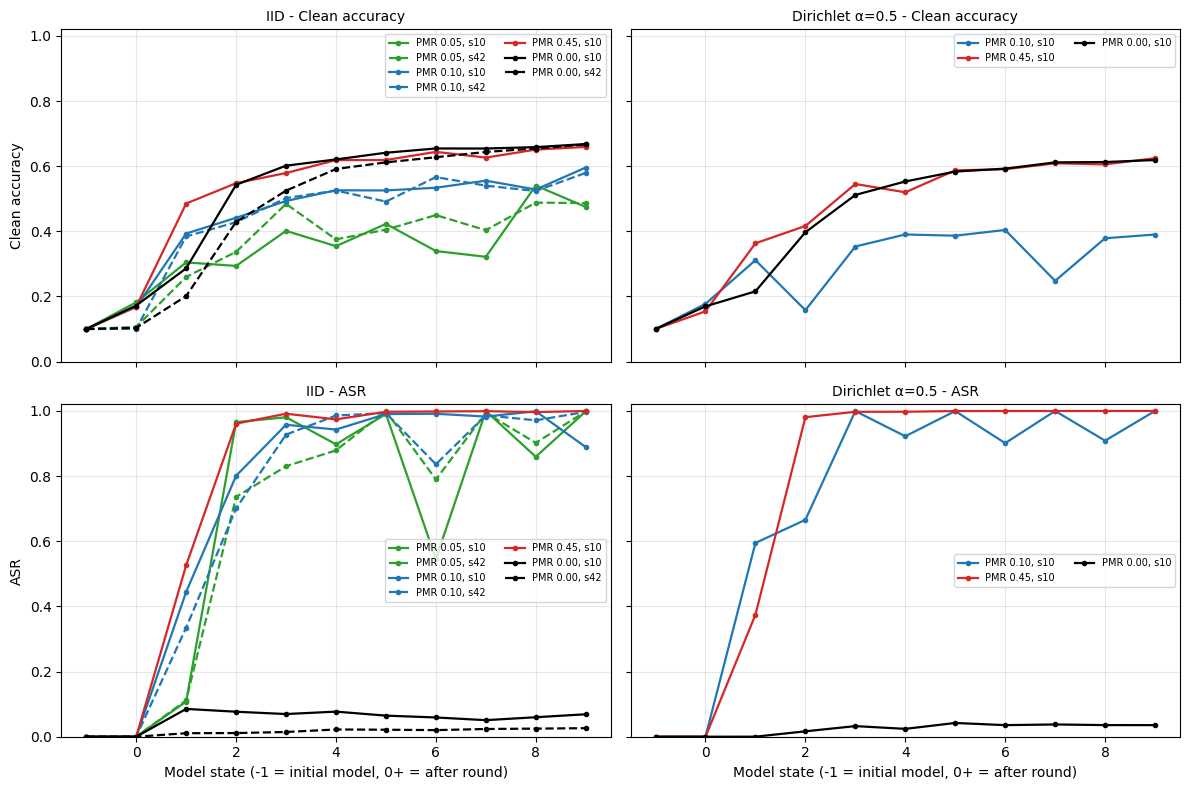

In [12]:
def short_label(row):
    part = row.get("partition", "?")
    p = f"Dir α={row.get('alpha', np.nan)}" if part == "dirichlet" else "IID"
    return f"{p}, PMR={row.get('pmr')}, seed={row.get('seed')}"

models_rounds_df = models_df.copy()
models_rounds_df["round_num"] = pd.to_numeric(
    models_rounds_df["model"].astype(str).str.extract(r"after_round_(\d+)")[0], errors="coerce")
models_rounds_df.loc[models_rounds_df["model"].astype(str).eq("theta_0"), "round_num"] = -1
models_rounds_df = models_rounds_df.dropna(subset=["round_num"])

PMR_COLORS = {0.0: "black", 0.05: "tab:green", 0.10: "tab:blue", 0.45: "tab:red"}
SEED_STYLES = {10: "-", 42: "--"}
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for i, (metric, ylab) in enumerate([("clean_accuracy", "Clean accuracy"), ("asr", "ASR")]):
    for j, part in enumerate(["iid", "dirichlet"]):
        ax = axes[i, j]
        for f, g in models_rounds_df[models_rounds_df["partition"] == part].groupby("file"):
            g = g.sort_values("round_num"); r = g.iloc[0]
            ax.plot(g["round_num"], g[metric], marker="o", ms=3, lw=1.6,
                    color=PMR_COLORS.get(round(float(r["pmr"]), 2), "gray"),
                    ls=SEED_STYLES.get(int(r["seed"]), ":"),
                    label=f"PMR {float(r['pmr']):.2f}, s{int(r['seed'])}")
        ax.set_title(("IID" if part == "iid" else "Dirichlet α=0.5") + f" - {ylab}", fontsize=10)
        ax.set_ylim(0, 1.02); ax.grid(True, alpha=.3)
        if i == 1: ax.set_xlabel("Model state (-1 = initial model, 0+ = after round)")
        if j == 0: ax.set_ylabel(ylab)
        ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "curves_faceted.png", dpi=220, bbox_inches="tight")
plt.show(); plt.close(fig)

## 8. Appendix figure: final clean accuracy vs ASR

Descriptive utility/attack-effectiveness plot, best kept in the appendix because labels overlap and the results table carries the same numbers. A clean run's ASR is still measured using the trigger recorded in its handoff, so label it as a clean-baseline trigger test, not evidence of an active attack. Seeds 10 and 42 use different triggers and target classes, so clean-baseline ASR is not directly comparable across seeds.

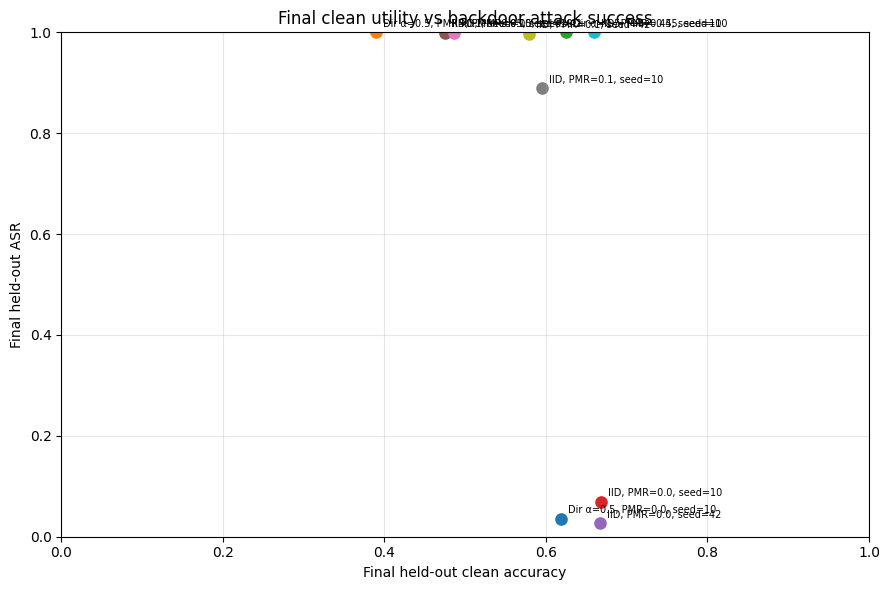

In [13]:
fig, ax = plt.subplots(figsize=(9, 6))
for _, r in final_summary_df.iterrows():
    label = short_label(r)
    ax.scatter(r["clean_accuracy"], r["asr"], s=65)
    ax.annotate(label, (r["clean_accuracy"], r["asr"]), xytext=(5, 4), textcoords="offset points", fontsize=7)
ax.set_xlabel("Final held-out clean accuracy")
ax.set_ylabel("Final held-out ASR")
ax.set_title("Final clean utility vs backdoor attack success")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.grid(True, alpha=.3)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "final_clean_accuracy_vs_asr.png", dpi=220, bbox_inches="tight"); plt.show(); plt.close(fig)

## 9. Figure: round-level detection

Main-text panel: every ground-truth malicious client plus only the benign clients flagged at least once (the rest are hidden and counted in the title). Green = malicious flagged, red = malicious not flagged, orange = benign flagged (false-positive event). Round 0 has no active attacker, so a red cell in round 0 is not a detection miss. Full per-run heatmaps (all clients, ground-truth clients in red tick labels) are saved as PNGs for the appendix.

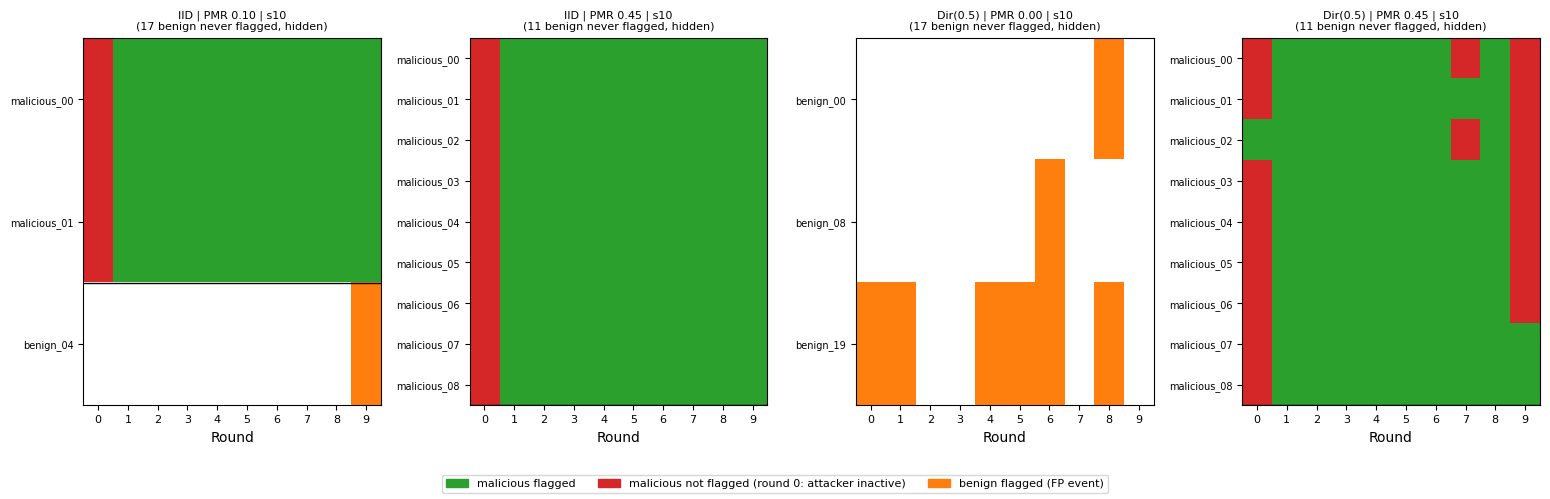

In [14]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

def detection_panel(runs, fname):
    cmap = ListedColormap(["white", "tab:orange", "tab:green", "tab:red"])
    fig, axes = plt.subplots(1, len(runs), figsize=(3.9 * len(runs), 5), squeeze=False)
    for ax, run in zip(axes[0], runs):
        f = next(k for k, v in FILE_TO_RUN.items() if v == run)
        m = metadata_df[metadata_df["file"] == f].iloc[0]
        truth = [c for c in str(m["ground_truth_clients"]).split(", ") if c and c != "nan"]
        rd_f = round_detection_df[round_detection_df["file"] == f].sort_values("round")
        flagged = {int(r["round"]): {x for x in str(r["detected_clients"]).split(", ") if x and x != "nan"}
                   for _, r in rd_f.iterrows()}
        rounds = sorted(flagged)
        ever = set().union(*flagged.values()) if flagged else set()
        rows = sorted(truth) + sorted(ever - set(truth))
        mat = np.zeros((max(1, len(rows)), len(rounds)))
        for i, c in enumerate(rows):
            for j, r in enumerate(rounds):
                hit = c in flagged[r]
                mat[i, j] = (2 if hit else 3) if c in truth else (1 if hit else 0)
        ax.imshow(mat, aspect="auto", cmap=cmap, vmin=0, vmax=3, interpolation="nearest")
        ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows, fontsize=7)
        ax.set_xticks(range(len(rounds))); ax.set_xticklabels(rounds, fontsize=8)
        ax.set_xlabel("Round")
        ax.set_title(f"{run}\n({int(m['num_clients']) - len(rows)} benign never flagged, hidden)", fontsize=8)
        if truth: ax.axhline(len(truth) - .5, c="k", lw=1)
    fig.legend(handles=[Patch(color="tab:green", label="malicious flagged"),
                        Patch(color="tab:red", label="malicious not flagged (round 0: attacker inactive)"),
                        Patch(color="tab:orange", label="benign flagged (FP event)")],
               loc="lower center", ncol=3, fontsize=8)
    fig.tight_layout(rect=(0, .07, 1, 1))
    fig.savefig(OUTPUT_DIR / fname, dpi=220, bbox_inches="tight")
    plt.show(); plt.close(fig)

# Edit these four labels if you want different runs in the main text (see RUN_ORDER above).
MAIN_PANEL_RUNS = [r for r in ["IID | PMR 0.10 | s10", "IID | PMR 0.45 | s10",
                               "Dir(0.5) | PMR 0.00 | s10", "Dir(0.5) | PMR 0.45 | s10"] if r in RUN_ORDER]
detection_panel(MAIN_PANEL_RUNS, "detection_panel_main.png")

In [15]:
# Appendix: one full heatmap per run (saved, not displayed, to keep the notebook readable).
for jp in eval_jsons:
    with open(jp, "r") as f: ev = json.load(f)
    det = ev.get("detection", {})
    per_round = det.get("per_round", [])
    if not per_round: continue
    truth = set(det.get("ground_truth", []))
    all_clients = sorted(set(det.get("detection_counts", {}).keys()) | truth)
    source_pt = HANDOFF_PATH_BY_NAME.get(jp.name.replace("_evaluation.json", ".pt"))
    try:
        h = load_handoff(source_pt)
        if h.get("round_history"):
            all_clients = sorted(h["round_history"][0]["updates"].keys())
    except Exception:
        pass
    all_clients = sorted(all_clients, key=lambda c: (c not in truth, c))   # malicious first
    mat = np.zeros((len(all_clients), len(per_round)), dtype=int)
    for j, r in enumerate(per_round):
        flagged = set(r.get("detected", []))
        for i, client in enumerate(all_clients): mat[i, j] = int(client in flagged)
    fig, ax = plt.subplots(figsize=(9, max(5, len(all_clients) * .22)))
    ax.imshow(mat, aspect="auto", interpolation="nearest", vmin=0, vmax=1, cmap="Greys")
    ax.set_yticks(range(len(all_clients))); ax.set_yticklabels(all_clients, fontsize=7)
    for lab in ax.get_yticklabels():
        if lab.get_text() in truth: lab.set_color("red")
    ax.set_xticks(range(len(per_round))); ax.set_xticklabels([r["round"] for r in per_round])
    ax.set_xlabel("Round"); ax.set_ylabel("Client (red = ground-truth malicious)")
    ax.set_title("Round-level detection: " + jp.name.replace("_evaluation.json", ""), fontsize=9)
    fig.tight_layout()
    safe = re.sub(r"[^A-Za-z0-9_.-]+", "_", jp.name.replace("_evaluation.json", ""))
    fig.savefig(OUTPUT_DIR / f"detection_heatmap_{safe}.png", dpi=200, bbox_inches="tight")
    plt.close(fig)
print("Saved", len(list(OUTPUT_DIR.glob("detection_heatmap_*.png"))), "appendix heatmaps.")

Saved 10 appendix heatmaps.


## 10. Threshold analysis

The final malicious set contains every client flagged in at least `tau × rounds` rounds. The sweep runs from `1/rounds` to 1.0 plus the union rule. It is **descriptive**: it was read off the same ten runs, so it is not independent validation of the threshold. The saved configuration records `tau = 0.5` at run time.

**10a. Detection frequency by ground-truth class**, and the range of tau that gives a perfect final set in each run.

,run,n_malicious,max_benign_freq,min_malicious_freq,benign_clients_ever_flagged,perfect_final_set_window
0,IID | PMR 0.00 | s10,0,0.1,NaN,2,tau > 0.1 (clean run)
1,IID | PMR 0.00 | s42,0,0.2,NaN,4,tau > 0.2 (clean run)
2,IID | PMR 0.05 | s10,1,0.2,0.9,5,0.2 < tau <= 0.9
3,IID | PMR 0.05 | s42,1,0.1,0.9,4,0.1 < tau <= 0.9
4,IID | PMR 0.10 | s10,2,0.1,0.9,1,0.1 < tau <= 0.9
5,IID | PMR 0.10 | s42,2,0.1,0.9,5,0.1 < tau <= 0.9
6,IID | PMR 0.45 | s10,9,0.0,0.9,0,0.0 < tau <= 0.9
7,Dir(0.5) | PMR 0.00 | s10,0,0.6,NaN,3,tau > 0.6 (clean run)
8,Dir(0.5) | PMR 0.10 | s10,2,0.3,0.9,4,0.3 < tau <= 0.9
9,Dir(0.5) | PMR 0.45 | s10,9,0.0,0.7,0,0.0 < tau <= 0.7


Across all runs: a perfect final set needs 0.6 < tau <= 0.7
Lowest malicious frequencies (closest to the threshold):


,run,min_malicious_freq,perfect_final_set_window
9,Dir(0.5) | PMR 0.45 | s10,0.7,0.0 < tau <= 0.7
2,IID | PMR 0.05 | s10,0.9,0.2 < tau <= 0.9
4,IID | PMR 0.10 | s10,0.9,0.1 < tau <= 0.9


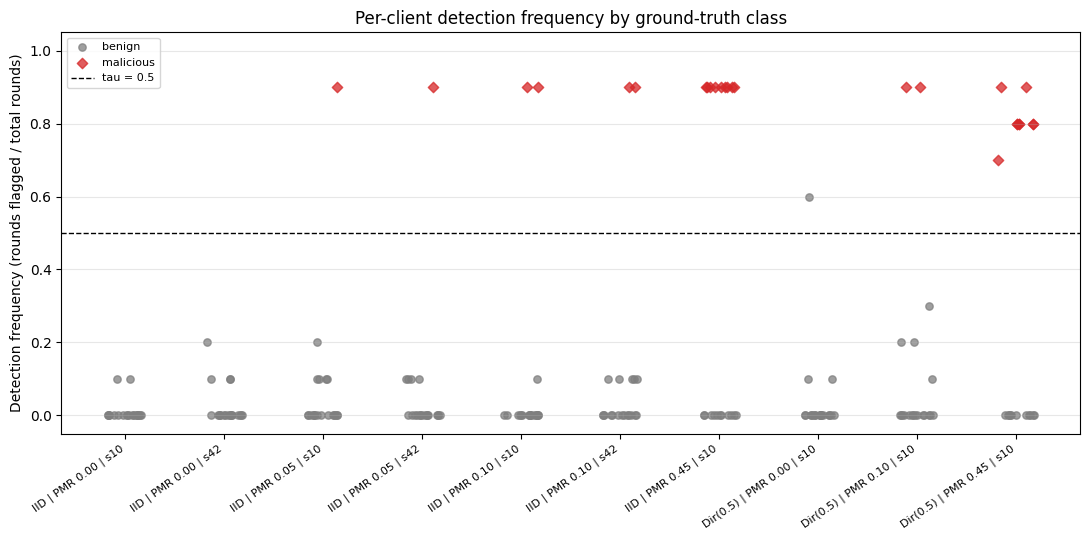

In [16]:
rows, strip = [], []
for _, m in metadata_df.iterrows():
    sub = detection_counts_df[detection_counts_df["file"] == m["file"]]
    R, n, nm = int(m["rounds_configured"]), int(m["num_clients"]), int(m["num_malicious_ground_truth"])
    mal = sub.loc[sub["is_ground_truth_malicious"], "detected_rounds"].tolist()
    ben = sub.loc[~sub["is_ground_truth_malicious"], "detected_rounds"].tolist()
    mal += [0] * (nm - len(mal))              # detection_counts only lists clients flagged at least once
    ben += [0] * ((n - nm) - len(ben))
    mal_f, ben_f = np.array(mal) / R, np.array(ben) / R
    lo = ben_f.max() if len(ben_f) else 0.0
    hi = mal_f.min() if len(mal_f) else np.nan
    if nm == 0:
        window = f"tau > {lo:.1f} (clean run)"
    elif hi > lo:
        window = f"{lo:.1f} < tau <= {hi:.1f}"
    else:
        window = "no separating tau (overlap)"
    rows.append({"run": m["run"], "n_malicious": nm, "max_benign_freq": lo, "min_malicious_freq": hi,
                 "benign_clients_ever_flagged": int((ben_f > 0).sum()), "perfect_final_set_window": window})
    strip += [(m["run"], v, "malicious") for v in mal_f] + [(m["run"], v, "benign") for v in ben_f]

window_df = pd.DataFrame(rows)
display(window_df)
window_df.to_csv(OUTPUT_DIR / "tau_window_per_run.csv", index=False)

att = window_df[window_df["n_malicious"] > 0]
g_lo, g_hi = window_df["max_benign_freq"].max(), att["min_malicious_freq"].min()
print(f"Across all runs: a perfect final set needs {g_lo:.1f} < tau <= {g_hi:.1f}"
      if g_hi > g_lo else "No single tau gives a perfect final set in every run.")
print("Lowest malicious frequencies (closest to the threshold):")
display(att.sort_values("min_malicious_freq").head(3)[["run", "min_malicious_freq", "perfect_final_set_window"]])

rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(11, 5.5))
xpos = {r: i for i, r in enumerate(RUN_ORDER)}
for kind, color, marker in [("benign", "tab:gray", "o"), ("malicious", "tab:red", "D")]:
    pts = [(xpos[r], v) for r, v, k in strip if k == kind]
    if pts:
        x, y = zip(*pts)
        ax.scatter(np.array(x) + rng.uniform(-.18, .18, len(x)), y, s=28, alpha=.75, c=color, marker=marker, label=kind)
ax.axhline(0.5, ls="--", c="k", lw=1, label="tau = 0.5")
ax.set_xticks(range(len(RUN_ORDER))); ax.set_xticklabels(RUN_ORDER, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("Detection frequency (rounds flagged / total rounds)")
ax.set_title("Per-client detection frequency by ground-truth class")
ax.set_ylim(-.05, 1.05); ax.grid(True, axis="y", alpha=.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "detection_frequency_separation.png", dpi=220, bbox_inches="tight")
plt.show(); plt.close(fig)

**10b. Final-set false positives and false negatives across the whole tau sweep**, and a direct comparison of tau = 0.5, 0.7 and 0.9. Malicious frequency cannot exceed 0.9 here (round 0 has no active attacker), so tau = 1.0 always misses attackers; a tau of 0.9 leaves zero slack.

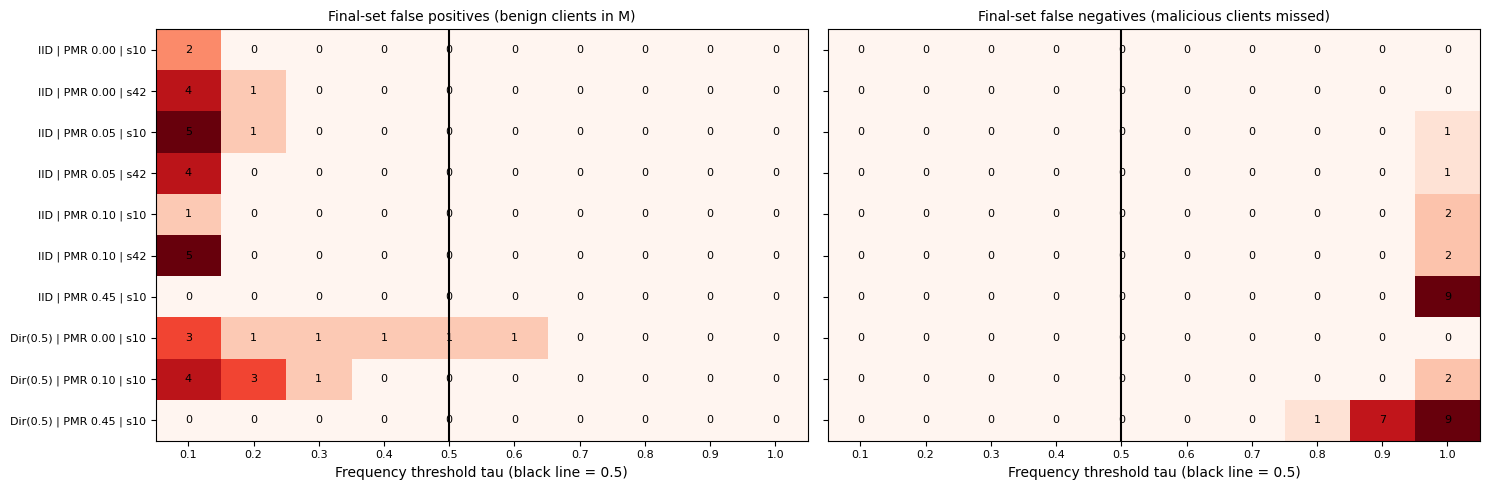

final_set_FP         final_set_FN        
tau                                0.5 0.7 0.9          0.5 0.7 0.9
run                                                                
IID | PMR 0.00 | s10                 0   0   0            0   0   0
IID | PMR 0.00 | s42                 0   0   0            0   0   0
IID | PMR 0.05 | s10                 0   0   0            0   0   0
IID | PMR 0.05 | s42                 0   0   0            0   0   0
IID | PMR 0.10 | s10                 0   0   0            0   0   0
IID | PMR 0.10 | s42                 0   0   0            0   0   0
IID | PMR 0.45 | s10                 0   0   0            0   0   0
Dir(0.5) | PMR 0.00 | s10            1   0   0            0   0   0
Dir(0.5) | PMR 0.10 | s10            0   0   0            0   0   0
Dir(0.5) | PMR 0.45 | s10            0   0   0            0   0   7

In [17]:
sw = threshold_df[threshold_df["rule"].astype(str).str.startswith("frequency_tau=")].copy()
sw["tau"] = pd.to_numeric(sw["rule"].str.extract(r"frequency_tau=([0-9.]+)")[0], errors="coerce")
sw["run"] = sw["file"].map(FILE_TO_RUN)
for c in ["fp", "fn", "tp"]:
    sw[c] = pd.to_numeric(sw[c], errors="coerce")

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (metric, title) in zip(axes, [("fp", "Final-set false positives (benign clients in M)"),
                                      ("fn", "Final-set false negatives (malicious clients missed)")]):
    piv = sw.pivot_table(index="run", columns="tau", values=metric, aggfunc="first").reindex(RUN_ORDER)
    piv.to_csv(OUTPUT_DIR / f"threshold_sweep_{metric}_pivot.csv")
    ax.imshow(piv.values, aspect="auto", cmap="Reds", vmin=0, vmax=max(1, np.nanmax(piv.values)))
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            if not np.isnan(v): ax.text(j, i, int(v), ha="center", va="center", fontsize=8)
    ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels([f"{t:.1f}" for t in piv.columns], fontsize=8)
    ax.set_yticks(range(len(RUN_ORDER))); ax.set_yticklabels(RUN_ORDER, fontsize=8)
    if 0.5 in [round(t, 2) for t in piv.columns]:
        ax.axvline([round(t, 2) for t in piv.columns].index(0.5), c="k", lw=1.5)
    ax.set_xlabel("Frequency threshold tau (black line = 0.5)"); ax.set_title(title, fontsize=10)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "threshold_sweep_fp_fn_heatmaps.png", dpi=220, bbox_inches="tight")
plt.show(); plt.close(fig)

cmp_rows = []
for tau in (0.5, 0.7, 0.9):
    s = sw[np.isclose(sw["tau"], tau)].set_index("run").reindex(RUN_ORDER)
    for r in RUN_ORDER:
        cmp_rows.append({"run": r, "tau": tau, "final_set_TP": s.loc[r, "tp"], "final_set_FP": s.loc[r, "fp"],
                         "final_set_FN": s.loc[r, "fn"], "M": s.loc[r, "M"] if "M" in s.columns else ""})
tau_compare_df = pd.DataFrame(cmp_rows)
tau_compare_wide = tau_compare_df.pivot(index="run", columns="tau", values=["final_set_FP", "final_set_FN"]).reindex(RUN_ORDER)
display(tau_compare_wide)
tau_compare_df.to_csv(OUTPUT_DIR / "tau_0p5_0p7_0p9_comparison.csv", index=False)

## 11. Summary of final-set detection metrics at the configured threshold

This selects the `frequency_tau=...` row corresponding to each handoff's configured `final_m_tau`, when available. It also retains the union-rule result separately. Verify that the configured threshold is the one you intend to report; do not choose it solely because it produces the best scores on these runs.

In [18]:
selected_rows = []
for _, meta in metadata_df.iterrows():
    fname = meta["file"]
    matching = threshold_df[threshold_df["file"] == fname]
    tau = meta.get("final_M_tau_saved")
    if pd.notna(tau):
        rule_name = f"frequency_tau={float(tau):.2f}"
        pick = matching[matching["rule"] == rule_name]
    else:
        pick = pd.DataFrame()
    if pick.empty:
        pick = matching[matching["rule"] == "union"]
        used_rule = "union (fallback; inspect config)"
    else:
        used_rule = rule_name
    for _, r in pick.iterrows():
        selected_rows.append({"file": fname, "partition": meta["partition"], "alpha": meta["dirichlet_alpha"],
                              "pmr": meta["pmr"], "seed": meta["seed"], "selected_rule": used_rule,
                              **{k: r.get(k) for k in ["tp","fp","fn","tn","precision","recall","f1","M"]}})
selected_detection_df = pd.DataFrame(selected_rows)
display(selected_detection_df)
selected_detection_df.to_csv(OUTPUT_DIR / "configured_threshold_detection_summary.csv", index=False)

,file,partition,alpha,pmr,seed,selected_rule,tp,fp,fn,tn,precision,recall,f1,M
0,handoff_0pmr_seed10_iid.pt,iid,NaN,0.00,10,frequency_tau=0.50,0,0,0,20,NaN,NaN,NaN,
1,handoff_0pmr_seed42_iid.pt,iid,NaN,0.00,42,frequency_tau=0.50,0,0,0,20,NaN,NaN,NaN,
2,handoff_005pmr_seed10_iid.pt,iid,NaN,0.05,10,frequency_tau=0.50,1,0,0,19,1.0,1.0,1.0,malicious_00
3,handoff_005pmr_seed42_iid.pt,iid,NaN,0.05,42,frequency_tau=0.50,1,0,0,19,1.0,1.0,1.0,malicious_00
4,handoff_010pmr_seed10_iid.pt,iid,NaN,0.10,10,frequency_tau=0.50,2,0,0,18,1.0,1.0,1.0,"malicious_00, malicious_01"
5,handoff_010pmr_seed42_iid.pt,iid,NaN,0.10,42,frequency_tau=0.50,2,0,0,18,1.0,1.0,1.0,"malicious_00, malicious_01"
6,handoff_045pmr_seed10_iid.pt,iid,NaN,0.45,10,frequency_tau=0.50,9,0,0,11,1.0,1.0,1.0,"malicious_00, malicious_01, malicious_02, mali..."
7,handoff_0pmr_seed10_dirichlet_05alpha.pt,dirichlet,0.5,0.00,10,frequency_tau=0.50,0,1,0,19,0.0,NaN,NaN,benign_19
8,handoff_010pmr_seed10_dirichlet_05alpha.pt,dirichlet,0.5,0.10,10,frequency_tau=0.50,2,0,0,18,1.0,1.0,1.0,"malicious_00, malicious_01"
9,handoff_045pmr_seed10_dirichlet_05alpha.pt,dirichlet,0.5,0.45,10,frequency_tau=0.50,9,0,0,11,1.0,1.0,1.0,"malicious_00, malicious_01, malicious_02, mali..."


## 12. Round-level false-positive events versus final-set false positives

These are different quantities. The first counts benign client-round detections; the second counts benign clients remaining in the final malicious set. Do not report them as if they were the same metric.

In [19]:
fp_summary = []
for _, meta in metadata_df.iterrows():
    fname = meta["file"]
    rd = round_detection_df[round_detection_df["file"] == fname]
    selected = selected_detection_df[selected_detection_df["file"] == fname]
    fp_summary.append({
        "file": fname, "partition": meta["partition"], "alpha": meta["dirichlet_alpha"],
        "pmr": meta["pmr"], "seed": meta["seed"],
        "round_level_fp_client_round_events": int(pd.to_numeric(rd["fp"], errors="coerce").fillna(0).sum()),
        "sum_round_level_fn_events": int(pd.to_numeric(rd["fn"], errors="coerce").fillna(0).sum()),
        "final_set_fp_clients": int(selected["fp"].iloc[0]) if len(selected) else np.nan,
        "final_set_fn_clients": int(selected["fn"].iloc[0]) if len(selected) else np.nan,
    })
fp_summary_df = pd.DataFrame(fp_summary)
display(fp_summary_df)
fp_summary_df.to_csv(OUTPUT_DIR / "false_positive_distinction.csv", index=False)

,file,partition,alpha,pmr,seed,round_level_fp_client_round_events,sum_round_level_fn_events,final_set_fp_clients,final_set_fn_clients
0,handoff_0pmr_seed10_iid.pt,iid,NaN,0.00,10,2,0,0,0
1,handoff_0pmr_seed42_iid.pt,iid,NaN,0.00,42,5,0,0,0
2,handoff_005pmr_seed10_iid.pt,iid,NaN,0.05,10,6,1,0,0
3,handoff_005pmr_seed42_iid.pt,iid,NaN,0.05,42,4,1,0,0
4,handoff_010pmr_seed10_iid.pt,iid,NaN,0.10,10,1,2,0,0
5,handoff_010pmr_seed42_iid.pt,iid,NaN,0.10,42,5,2,0,0
6,handoff_045pmr_seed10_iid.pt,iid,NaN,0.45,10,0,9,0,0
7,handoff_0pmr_seed10_dirichlet_05alpha.pt,dirichlet,0.5,0.00,10,8,0,1,0
8,handoff_010pmr_seed10_dirichlet_05alpha.pt,dirichlet,0.5,0.10,10,8,2,0,0
9,handoff_045pmr_seed10_dirichlet_05alpha.pt,dirichlet,0.5,0.45,10,0,17,0,0


## 12b. Table 1: consolidated results

One table for the report: final utility and ASR, round-level false-positive rate (events per benign client-round), recall over active attack rounds, and final-set TP/FP/FN at the configured threshold. Clean runs have no positives, so precision/recall/F1 are undefined there and false-positive counts are reported instead. ASR is attack effectiveness (detected updates are retained in aggregation), not a defense metric.

In [20]:
t = (final_summary_df[["file", "clean_accuracy", "asr"]]
     .merge(fp_summary_df[["file", "round_level_fp_client_round_events", "final_set_fp_clients", "final_set_fn_clients"]], on="file")
     .merge(selected_detection_df[["file", "tp"]].rename(columns={"tp": "final_set_tp"}), on="file")
     .merge(active_df[["file", "active_rounds", "malicious_missed_in_active_rounds", "active_round_recall"]], on="file")
     .merge(metadata_df[["file", "run", "rounds_configured", "num_clients", "num_malicious_ground_truth"]], on="file"))
n_ben = t["num_clients"].astype(int) - t["num_malicious_ground_truth"].astype(int)
t["benign_client_rounds"] = n_ben * t["rounds_configured"].astype(int)
t["round_FP_rate"] = (t["round_level_fp_client_round_events"] / t["benign_client_rounds"]).round(4)
t["clean_accuracy_%"] = (100 * t["clean_accuracy"]).round(2)
t["ASR_%"] = (100 * t["asr"]).round(2)
table1 = t.set_index("run").loc[RUN_ORDER][[
    "clean_accuracy_%", "ASR_%", "round_level_fp_client_round_events", "benign_client_rounds", "round_FP_rate",
    "active_rounds", "malicious_missed_in_active_rounds", "active_round_recall",
    "final_set_tp", "final_set_fp_clients", "final_set_fn_clients"]]
display(table1)
table1.to_csv(OUTPUT_DIR / "table1_main_results.csv")

,clean_accuracy_%,ASR_%,round_level_fp_client_round_events,benign_client_rounds,round_FP_rate,active_rounds,malicious_missed_in_active_rounds,active_round_recall,final_set_tp,final_set_fp_clients,final_set_fn_clients
run,,,,,,,,,,,
IID | PMR 0.00 | s10,66.79,6.89,2,200,0.0100,0,0,NaN,0,0,0
IID | PMR 0.00 | s42,66.65,2.62,5,200,0.0250,0,0,NaN,0,0,0
IID | PMR 0.05 | s10,47.49,99.87,6,190,0.0316,9,0,1.000000,1,0,0
IID | PMR 0.05 | s42,48.65,99.88,4,190,0.0211,9,0,1.000000,1,0,0
IID | PMR 0.10 | s10,59.57,88.90,1,180,0.0056,9,0,1.000000,2,0,0
IID | PMR 0.10 | s42,57.93,99.72,5,180,0.0278,9,0,1.000000,2,0,0
IID | PMR 0.45 | s10,65.91,99.99,0,110,0.0000,9,0,1.000000,9,0,0
Dir(0.5) | PMR 0.00 | s10,61.88,3.56,8,200,0.0400,0,0,NaN,0,1,0
Dir(0.5) | PMR 0.10 | s10,39.01,100.00,8,180,0.0444,9,0,1.000000,2,0,0


## 12c. Optional: how many rounds of detection are needed? (offline replay, exploratory)

Replays the frequency rule using only the first `r` rounds of each run's recorded detections, with the same tau. This uses existing results only, with no new training. It indicates how early the correct set appears and how contaminated the model already is at that round; it does not test an actual earlier-unlearning pipeline.

In [21]:
TAU_REPLAY = 0.5
asr_lookup = models_rounds_df.set_index(["file", "round_num"])[["clean_accuracy", "asr"]]
rows = []
for f, g in round_detection_df.sort_values("round").groupby("file"):
    meta = metadata_df.loc[metadata_df["file"] == f].iloc[0]
    truth = {c for c in str(meta["ground_truth_clients"]).split(", ") if c and c != "nan"}
    flags = [{x for x in str(d).split(", ") if x and x != "nan"} for d in g["detected_clients"]]
    for r in range(1, len(flags) + 1):
        cnt = {c: sum(c in s for s in flags[:r]) for c in set().union(*flags[:r])}
        M = {c for c, n in cnt.items() if n >= TAU_REPLAY * r - 1e-9}
        key = (f, r - 1)
        rows.append({"run": FILE_TO_RUN[f], "rounds_used": r, "TP": len(M & truth), "FP": len(M - truth),
                     "FN": len(truth - M), "model_clean_acc": asr_lookup["clean_accuracy"].get(key, np.nan),
                     "model_asr": asr_lookup["asr"].get(key, np.nan)})
replay_df = pd.DataFrame(rows)
replay_df["perfect_set"] = (replay_df["FP"] == 0) & (replay_df["FN"] == 0)
first_perfect = (replay_df[replay_df["perfect_set"]].groupby("run")["rounds_used"].min()
                 .reindex(RUN_ORDER).rename("first_round_count_with_perfect_set"))
display(first_perfect.to_frame())
replay_df.to_csv(OUTPUT_DIR / "early_detection_replay.csv", index=False)

,first_round_count_with_perfect_set
run,
IID | PMR 0.00 | s10,1.0
IID | PMR 0.00 | s42,3.0
IID | PMR 0.05 | s10,2.0
IID | PMR 0.05 | s42,2.0
IID | PMR 0.10 | s10,2.0
IID | PMR 0.10 | s42,2.0
IID | PMR 0.45 | s10,2.0
Dir(0.5) | PMR 0.00 | s10,NaN
Dir(0.5) | PMR 0.10 | s10,3.0


## 13. Export all tables and figures

The output directory contains CSV tables and PNG figures. Review every table and figure for completeness and correct labels before including it in the BTP.

In [22]:
print("Outputs written to:", OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.iterdir()):
    if p.is_file(): print(f"{p.name:55s} {p.stat().st_size/1024:.1f} KB")

Outputs written to: /kaggle/working/crowdguard_report_outputs
active_round_detection_summary.csv                      1.0 KB
client_detection_frequencies.csv                        13.5 KB
code_version_audit.csv                                  0.6 KB
configured_threshold_detection_summary.csv              1.3 KB
curves_faceted.png                                      398.5 KB
detection_frequency_separation.png                      127.6 KB
detection_heatmap_handoff_005pmr_seed10_iid.png         78.1 KB
detection_heatmap_handoff_005pmr_seed42_iid.png         78.4 KB
detection_heatmap_handoff_010pmr_seed10_dirichlet_05alpha.png 80.2 KB
detection_heatmap_handoff_010pmr_seed10_iid.png         77.5 KB
detection_heatmap_handoff_010pmr_seed42_iid.png         78.0 KB
detection_heatmap_handoff_045pmr_seed10_dirichlet_05alpha.png 80.7 KB
detection_heatmap_handoff_045pmr_seed10_iid.png         78.1 KB
detection_heatmap_handoff_0pmr_seed10_dirichlet_05alpha.png 80.1 KB
detection_heatmap_handoff_0

## 14. Interpretation safeguards for the report

- Report exact completed configurations; do not claim results for the failed Dirichlet α = 0.1 runs (exit code -9, cause unconfirmed).
- A second seed at a configuration provides a limited reproducibility check, not a robust estimate of variance.
- The seed controls the model initialization, the data partition, **and the trigger position, pattern and target class**. Seeds 10 and 42 therefore differ in trigger and target class, which can affect clean-baseline ASR; this is untested as an explanation.
- Malicious clients take the last loader indices, so changing PMR moves the malicious roles to different data shards for a fixed seed. Do not attribute PMR differences to PMR alone.
- The attack starts at round 1. Round 0 has no active attacker, so report recall over active rounds and treat round-0 flags in attacked runs as false positives.
- Frequency is divided by all rounds, so a malicious client's frequency is at most 0.9 for 10 rounds and tau = 1.0 always misses attackers.
- Clean accuracy and ASR are measured on the held-out evaluation subset, excluding the KD-reference images. ASR excludes images whose true label is already the target class.
- Keep round-level false-positive **events** separate from final-set false-positive **clients**.
- The frequency threshold is an empirical design choice (tau = 0.5 was the configured value); the sweep is descriptive, not independent validation.
- The attack uses inverse-PMR scaling (N/m), and these experiments do not isolate its causal effect unless scaling is varied in a controlled comparison. Non-monotonic accuracy/ASR across PMR is an observation with confounds, not an established effect.
- Models were trained from random initialization for 10 rounds and had not converged (clean accuracy about 48–66%); the original CrowdGuard evaluation starts attacks from a converged model, so results are not directly comparable to the paper's.
- Dirichlet partitions use all 50,000 images with unequal client sizes (minimum 10) and equal-weight FedAvg; the 2,500 samples per client figure applies to IID only.
- The implementation retains detected updates during aggregation; explain this as a detection-only adaptation for the downstream unlearning workflow, not as an exact reproduction of filtering behavior in the original CrowdGuard method.
- Do not infer training-loss curves or wall-clock comparisons if those values were not recorded in the handoff/logs.